# 09 · Critic-free policy optimisation: ReMax, RLOO, REINFORCE++, GRPO, Dr. GRPO, DAPO, GSPO, CISPO

> **Goal of this notebook.** Notebook 07 trained an LLM with PPO, which needs **four** networks
> (policy, reference, reward model, value/critic). Since 2023 almost every reasoning model (DeepSeek-R1,
> Qwen3, Kimi, MiniMax-M1, ...) has been trained with a *critic-free* method instead: sample several
> answers per prompt and use **the other answers as the baseline**. This notebook derives and implements
> the whole family from scratch, trains every one of them on the same toy task, and compares them.

```mermaid
flowchart LR
    N04[04 REINFORCE] --> N05[05 Actor-critic / GAE] --> N06[06 PPO] --> N07[07 RLHF with PPO]
    N07 --> N09
    subgraph N09[09 Critic-free family - YOU ARE HERE]
      direction TB
      RM[ReMax] --- RL[RLOO] --- RPP[REINFORCE++]
      G[GRPO] --- DG[Dr. GRPO] --- DA[DAPO] --- GS[GSPO] --- CI[CISPO]
    end
    N09 --> N10[10 Reasoning RLVR]
    N09 --> N12[12 RL for VLMs]
    style N09 fill:#dbeafe,stroke:#2563eb
```

**What you need from earlier notebooks**

| Idea | Where | One-line reminder |
|---|---|---|
| Policy gradient | 04 | $\nabla J = \mathbb{E}[\,A \,\nabla \log \pi(y\mid x)\,]$ |
| Baseline | 04 | subtracting any $b$ that does not depend on the action keeps the gradient unbiased and cuts variance |
| Importance ratio + clipping | 06 | $\rho=\pi_\theta/\pi_{\text{old}}$, clip it to $[1-\varepsilon, 1+\varepsilon]$ so a single batch can't move the policy too far |
| KL to a reference | 07 | keep the fine-tuned model close to the SFT model |

## 1 · Why drop the critic?

In PPO-RLHF (notebook 07) the advantage of each token comes from a learned **value model** $V_\phi$:
$A_t = \text{GAE}(r_t + V_\phi(s_{t+1}) - V_\phi(s_t))$. For LLMs that critic is expensive and hard to train:

1. **Memory and compute.** The critic is normally the same size as the policy. With a 70B policy you need
   another 70B network, its gradients and its Adam state.
2. **The reward is sparse.** Reasoning tasks give one number, e.g. "the final answer is correct", at the very
   end. The critic has to guess, token by token, how likely a half-written proof is to end up correct. Early
   in training those guesses are poor, so the advantages are poor too.
3. **We can sample instead.** For a language model, drawing 8 or 16 answers to the same prompt is cheap
   with a fast inference engine. The *average reward of those answers* is a Monte-Carlo estimate of
   $V(x)$ for the prompt, and it is never "under-trained".

> **Analogy.** A teacher grading one essay has to judge it against some imagined "average essay"
> (that's the critic). A teacher grading the **whole class's** essays on the same question can simply
> compare each essay to the others. Critic-free methods grade the class.

```mermaid
flowchart TB
    subgraph PPO["PPO-RLHF (notebook 07)"]
      direction LR
      P1[Policy] -->|1 sample / prompt| R1[Reward model]
      P1 --> V1[Value model<br/>same size as policy]
      R1 --> GAE[GAE advantages<br/>per token]
      V1 --> GAE
      REF1[Reference] -.KL.-> P1
    end
    subgraph GRPO["Critic-free (this notebook)"]
      direction LR
      P2[Policy] -->|G samples / prompt| R2[Reward / verifier]
      R2 --> GN[Compare inside the group<br/>A_i = r_i - mean]
      REF2[Reference<br/>optional] -.KL.-> P2
    end
    PPO ~~~ GRPO
```

| | PPO-RLHF | Critic-free (GRPO & co.) |
|---|---|---|
| networks in memory | policy, reference, reward, **value** | policy, (reference), reward/verifier |
| baseline | learned $V_\phi(s_t)$ for every token | mean (or leave-one-out mean, or greedy) reward of the group |
| samples per prompt | 1 (usually) | $G$ = 4 to 64 |
| credit assignment | per token, via GAE | the same advantage for every token of a response |

### 1.1 · The one theorem behind the whole family: baselines are free

For a prompt $x$ and a response $y\sim\pi_\theta(\cdot\mid x)$ with reward $r(x,y)$:

$$\nabla_\theta J = \mathbb{E}_{y\sim\pi_\theta}\big[\,r(x,y)\,\nabla_\theta\log\pi_\theta(y\mid x)\,\big].$$

Subtract any $b$ that **does not depend on $y$**:

$$\mathbb{E}_{y}\big[b\,\nabla_\theta\log\pi_\theta(y\mid x)\big]
 = b\sum_y \pi_\theta(y\mid x)\frac{\nabla_\theta\pi_\theta(y\mid x)}{\pi_\theta(y\mid x)}
 = b\,\nabla_\theta\underbrace{\sum_y\pi_\theta(y\mid x)}_{=1} = 0 .$$

So $\mathbb{E}[(r-b)\nabla\log\pi] = \nabla J$ for *every* such $b$. Bias does not change, but variance does:
the best constant baseline is close to $\mathbb{E}[r\mid x]$, i.e. $V(x)$. Each member of the family is a
different answer to the question **"how do I estimate $V(x)$ without a critic?"**

| Method | Baseline $b$ for sample $i$ of prompt $x$ |
|---|---|
| ReMax | reward of the **greedy** answer to $x$ |
| RLOO | mean reward of the **other** $G-1$ samples of $x$ |
| GRPO | mean reward of **all** $G$ samples (then divide by their std) |
| REINFORCE++ | mean over the **whole batch** (all prompts), then normalise over the batch |

The remaining methods (Dr. GRPO, DAPO, GSPO, CISPO) keep a group baseline and change **how the loss is
aggregated, clipped or importance-weighted**.

## 2 · The toy task and the shared plumbing

Same model as notebooks 04-07: `TinyGPT` from `rlkit` (about 110k parameters). The task is one-digit
addition, `"3+4="` → `"7"` then `<eos>`, restricted to operands 0-5 (36 problems). The reward is
**verifiable**: 1 if the decoded answer exactly equals the true sum, otherwise 0. That is exactly the
"RL with verifiable rewards" (RLVR) setting used for maths and code (notebook 10).

We start from a short supervised warm-up: 50 SFT steps leave the model right roughly 1 time in 4 when
sampling. That matters. If the warm-up is too good, every sample in a group is correct, all
advantages are 0 and nothing is learned. If it is too bad, every sample is wrong, and again
nothing is learned.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import copy, math, random, time
from collections import defaultdict
from dataclasses import dataclass
from typing import Callable, Optional

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from rlkit import COLORS, Animator, plot_curves, setup_style, smooth
from rlkit.viz import asset_path, draw_arrow, draw_box, save_figure, show_frame
from rlkit.toy_lm import (AdditionTask, CharTokenizer, count_parameters, evaluate, generate, kl_k3,
                          make_policy, masked_mean, sequence_logprobs, sft_train, token_entropy)

setup_style()
torch.set_num_threads(4)

TOK = CharTokenizer()
TASK = AdditionTask(TOK, digits=1, seed=0)
PROBLEMS = [(p, a) for p, a in TASK.all_problems() if int(p[0]) < 6 and int(p[2]) < 6]
PROMPT_LEN = 5          # "<bos>3+4="
MAX_NEW = 4             # answers need at most 3 tokens ("10" + <eos>); 1 spare token lets the model ramble
print(len(PROBLEMS), "problems, e.g.", PROBLEMS[:4])

36 problems, e.g. [('0+0=', '0'), ('0+1=', '1'), ('0+2=', '2'), ('0+3=', '3')]


In [3]:
# Supervised warm-up: deliberately short so the policy is "sometimes right".
BASE = make_policy(TOK, seed=0)
TASK.rng.seed(0)
sft_hist = sft_train(BASE, lambda: TASK.sft_batch(32, PROBLEMS), steps=50, prompt_len=PROMPT_LEN)
BASE.eval()
for p in BASE.parameters():
    p.requires_grad_(False)

torch.manual_seed(0)
BASE_GREEDY = evaluate(BASE, TASK, PROBLEMS)
BASE_SAMPLED = np.mean([evaluate(BASE, TASK, PROBLEMS, greedy=False) for _ in range(5)])
print(f"TinyGPT with {count_parameters(BASE):,} parameters")
print(f"after warm-up: greedy accuracy {BASE_GREEDY:.2f}, sampled (T=1) accuracy {BASE_SAMPLED:.2f}")

TinyGPT with 111,360 parameters
after warm-up: greedy accuracy 0.31, sampled (T=1) accuracy 0.22


### 2.1 · Group rollouts

Every method in this notebook samples a **group** of $G$ responses per prompt. We lay a batch out as
`P` prompts × `G` samples = `B` rows, with the `G` samples of a prompt in consecutive rows, so
`rewards.view(P, G)` gives one row per group.

```mermaid
flowchart LR
    Q["P prompts<br/>'3+4=' '1+5=' ..."] -->|repeat each G times| QG["B = P x G rows"]
    QG -->|"generate (T = 1.0)"| Y["responses + response_mask"]
    Y -->|verifier| R["rewards (B,)"]
    R -->|"view(P, G)"| GR["group rewards (P, G)"]
    GR -->|algorithm-specific| A["advantages (B, T)"]
    Y -->|"sequence_logprobs (no grad)"| OLD["old / ref log-probs"]
```

In [4]:
def pad_cat(tensors, value=0.0):
    """Concatenate (b_i, T_i) tensors along dim 0, right-padding each to the longest T."""
    T = max(t.shape[1] for t in tensors)
    return torch.cat([F.pad(t, (0, T - t.shape[1]), value=value) for t in tensors], dim=0)


def sample_groups(policy, n_prompts, G, temperature=1.0):
    """Sample G responses for each of n_prompts random problems. Returns a dict of tensors."""
    prompt_ids, answers = TASK.batch(n_prompts, PROBLEMS)
    rows = prompt_ids.repeat_interleave(G, dim=0)              # group members are adjacent rows
    answers_rep = [a for a in answers for _ in range(G)]
    seq, mask = generate(policy, rows, MAX_NEW, temperature=temperature)
    acc = TASK.reward(seq, PROMPT_LEN, answers_rep)
    return {"prompt_ids": prompt_ids, "answers": answers, "seq": seq, "mask": mask, "acc": acc}


demo = sample_groups(BASE, n_prompts=2, G=6)
for i in range(12):
    prompt = TOK.decode(demo["seq"][i, :PROMPT_LEN])
    resp = TOK.decode(demo["seq"][i, PROMPT_LEN:])
    print(f"group {i // 6}  {prompt}{resp!r:8} reward={demo['acc'][i]:.0f}")

group 0  3+3='5'      reward=0
group 0  3+3='5'      reward=0
group 0  3+3='6'      reward=1
group 0  3+3='5'      reward=0
group 0  3+3='6'      reward=1
group 0  3+3='4'      reward=0
group 1  2+2='4'      reward=1
group 1  2+2='4'      reward=1
group 1  2+2='4'      reward=1
group 1  2+2='5'      reward=0
group 1  2+2='2'      reward=0
group 1  2+2='3'      reward=0


### 2.2 · One training loop for every algorithm

Every algorithm below is just **two small functions**:

* `advantage_fn(batch) -> (B, T)`: one advantage per response token. Most methods give every token
  of a response the same value.
* `loss_fn(logp, adv, batch) -> scalar`: the surrogate loss to minimise.

…and a few flags (number of PPO epochs, dynamic sampling, reward shaping). The harness below does
the rest: sample, score with the policy before the update ("old") and the frozen reference, run a few
gradient epochs, and log metrics. It contains **no algorithm-specific logic**, so differences in the
curves at the end come only from the advantage and loss functions.

In [5]:
@dataclass
class Algorithm:
    """A critic-free policy-optimisation method = advantage estimator + surrogate loss + options."""
    name: str
    advantage_fn: Callable[[dict], torch.Tensor]
    loss_fn: Callable[[torch.Tensor, torch.Tensor, dict], torch.Tensor]
    epochs: int = 2                    # gradient steps per batch (1 = purely on-policy REINFORCE)
    dynamic_sampling: bool = False     # DAPO: drop groups whose rewards are all equal, resample
    needs_greedy: bool = False         # ReMax: also decode a greedy answer per prompt
    reward_shaping: Optional[Callable[[dict], torch.Tensor]] = None   # DAPO overlong shaping
    color: str = COLORS["policy"]


def collect(policy, ref, algo, n_prompts, G, temperature=1.0, max_tries=4):
    """Roll out one batch and attach everything the advantage/loss functions might need."""
    batch = sample_groups(policy, n_prompts, G, temperature)
    raw_acc = batch["acc"].clone()
    if algo.dynamic_sampling:
        # Keep only groups with reward variance; top the batch up with fresh groups (DAPO).
        def informative(b):
            g = b["acc"].view(-1, G)
            return g.std(1) > 0
        keep = [batch]
        n_kept = int(informative(batch).sum())
        tries = 1
        while n_kept < n_prompts and tries < max_tries:
            extra = sample_groups(policy, n_prompts, G, temperature)
            raw_acc = torch.cat([raw_acc, extra["acc"]])
            keep.append(extra)
            n_kept += int(informative(extra).sum())
            tries += 1
        rows, prompts, answers = [], [], []
        for b in keep:
            ok = informative(b)
            for gi in torch.nonzero(ok).flatten().tolist():
                rows.extend(range(gi * G, (gi + 1) * G))
            prompts.append(b["prompt_ids"][ok])
            answers += [a for a, k in zip(b["answers"], ok.tolist()) if k]
        seq = pad_cat([b["seq"] for b in keep], value=TOK.PAD)
        mask = pad_cat([b["mask"] for b in keep])
        acc = torch.cat([b["acc"] for b in keep])
        rows = torch.tensor(rows[: n_prompts * G], dtype=torch.long)
        batch = {"prompt_ids": torch.cat(prompts)[:n_prompts], "answers": answers[:n_prompts],
                 "seq": seq[rows], "mask": mask[rows], "acc": acc[rows]}
    batch["raw_acc"] = raw_acc                   # unfiltered accuracy, for honest logging
    batch["G"] = G
    batch["r"] = batch["acc"].clone()
    if algo.reward_shaping is not None:
        batch["r"] = batch["r"] + algo.reward_shaping(batch)
    if algo.needs_greedy and len(batch["answers"]):
        gseq, _ = generate(policy, batch["prompt_ids"], MAX_NEW, greedy=True)
        batch["r_greedy"] = TASK.reward(gseq, PROMPT_LEN, batch["answers"])
    with torch.no_grad():
        batch["old_logp"] = sequence_logprobs(policy, batch["seq"])
        batch["ref_logp"] = sequence_logprobs(ref, batch["seq"])
    return batch


def train(algo, steps=200, n_prompts=16, G=8, lr=1e-3, seed=1, temperature=1.0, eval_every=10, hook=None):
    """Train a fresh copy of BASE with `algo`. Returns (policy, history dict)."""
    policy = copy.deepcopy(BASE).train()
    for p in policy.parameters():
        p.requires_grad_(True)
    opt = torch.optim.AdamW(policy.parameters(), lr=lr, weight_decay=0.0)
    TASK.rng.seed(seed)
    torch.manual_seed(seed)
    hist = defaultdict(list)
    t0 = time.perf_counter()
    for step in range(steps):
        batch = collect(policy, BASE, algo, n_prompts, G, temperature)
        hist["reward"].append(batch["raw_acc"].mean().item())
        if batch["seq"].shape[0] == 0:          # dynamic sampling found nothing informative
            continue
        adv = algo.advantage_fn(batch)
        for _ in range(algo.epochs):
            logp = sequence_logprobs(policy, batch["seq"])
            loss = algo.loss_fn(logp, adv, batch)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
            opt.step()
        g = batch["acc"].view(-1, G)
        hist["zero_var_groups"].append((g.std(1) == 0).float().mean().item())
        hist["entropy"].append(token_entropy(policy, batch["seq"], batch["mask"]).item())
        hist["length"].append(batch["mask"].sum(1).float().mean().item())
        with torch.no_grad():
            hist["kl"].append(masked_mean(kl_k3(sequence_logprobs(policy, batch["seq"]),
                                                batch["ref_logp"]), batch["mask"]).item())
        if step % eval_every == 0 or step == steps - 1:
            hist["eval_step"].append(step)
            hist["greedy_acc"].append(evaluate(policy, TASK, PROBLEMS))
        if hook is not None:
            hook(step, policy, batch, adv)
    hist["seconds"] = time.perf_counter() - t0
    return policy, hist


RESULTS = {}   # name -> history, filled in as we go


def report(name, hist):
    print(f"{name:12s} sampled reward {np.mean(hist['reward'][:10]):.2f} -> {np.mean(hist['reward'][-20:]):.2f} | "
          f"greedy acc {BASE_GREEDY:.2f} -> {hist['greedy_acc'][-1]:.2f} | "
          f"entropy {hist['entropy'][-1]:.2f} | len {hist['length'][-1]:.2f} | {hist['seconds']:.0f}s")

The three **loss aggregations** that keep coming up deserve their own names. Given a per-token loss
matrix $\ell_{i,t}$ and the response mask:

$$\underbrace{\frac1G\sum_i\frac1{|o_i|}\sum_t \ell_{i,t}}_{\text{sequence-mean (GRPO)}}\qquad
\underbrace{\frac1{\sum_i|o_i|}\sum_i\sum_t \ell_{i,t}}_{\text{token-mean (DAPO)}}\qquad
\underbrace{\frac1{G\,L_{\max}}\sum_i\sum_t \ell_{i,t}}_{\text{constant (Dr. GRPO)}}$$

In [6]:
def agg_sequence_mean(loss_tok, mask):
    """Average inside each response, then over responses (GRPO): short responses weigh more per token."""
    return masked_mean(loss_tok, mask, dim=1).mean()


def agg_token_mean(loss_tok, mask):
    """Every token in the batch counts equally (DAPO)."""
    return masked_mean(loss_tok, mask)


def agg_constant(loss_tok, mask, max_len=MAX_NEW):
    """Sum over tokens, divide by a constant (Dr. GRPO): no dependence on the sampled lengths."""
    return (loss_tok * mask).sum() / (mask.shape[0] * max_len)


def broadcast(seq_adv, mask):
    """Give every response token its sequence's advantage: (B,) -> (B, T)."""
    return seq_adv[:, None] * mask

## 3 · ReMax: the greedy answer is the baseline

**Paper.** Li et al., 2023, *"ReMax: A Simple, Effective, and Efficient Reinforcement Learning Method for
Aligning Large Language Models"*.

**Intuition.** Before grading a sampled answer, ask the model for its *best guess*, the greedy decode.
If the sample is better than the greedy answer, push it up. If it is worse, push it down. The greedy
reward is a cheap, prompt-specific estimate of "how good the model already is on this prompt".

**Math.** For each prompt $x$ draw $y\sim\pi_\theta$ and the greedy $\bar y = \arg\max$ decode:

$$\nabla_\theta J \approx \big(r(x,y) - r(x,\bar y)\big)\,\nabla_\theta\log\pi_\theta(y\mid x).$$

$\bar y$ does not depend on the random sample $y$, so by §1.1 the estimator is unbiased. ReMax is plain
REINFORCE: one gradient step per batch and no ratio clipping. The original paper uses one sample per
prompt. Here we reuse the same $G$ samples as the other methods so the comparison is fair.

**Algorithm steps**

1. **Sample.** For each prompt draw $G$ responses at temperature 1, plus **one greedy** response.
2. **Score.** Run the verifier on all of them, giving $r_i$ and $r_{\text{greedy}}$.
3. **Advantage.** $A_i = r_i - r_{\text{greedy}}$. A sample that beats the model's own best guess gets
   $A>0$.
4. **Update.** Minimise $-\frac1B\sum_i A_i\sum_t\log\pi_\theta(o_{i,t})$, one step (on-policy).

In [7]:
def remax_advantage(batch):
    """A_i = r_i - r(greedy answer of the same prompt)."""
    baseline = batch["r_greedy"].repeat_interleave(batch["G"])
    return broadcast(batch["r"] - baseline, batch["mask"])


def reinforce_loss(logp, adv, batch):
    """Plain REINFORCE: -A * log pi, summed over the response, averaged over responses."""
    return -((adv * logp * batch["mask"]).sum(1)).mean()


# Tiny standalone check: 1 group of 4 samples, greedy answer was correct (r=1).
toy = {"r": torch.tensor([1., 0., 1., 0.]), "r_greedy": torch.tensor([1.]), "G": 4, "mask": torch.ones(4, 1)}
print("ReMax advantages:", remax_advantage(toy).flatten().tolist(), "(wrong samples are pushed down, right ones get 0)")

ReMax advantages: [0.0, -1.0, 0.0, -1.0] (wrong samples are pushed down, right ones get 0)


In [8]:
REMAX = Algorithm("ReMax", remax_advantage, reinforce_loss, epochs=1, needs_greedy=True, color="#0891b2")
_, RESULTS["ReMax"] = train(REMAX)
report("ReMax", RESULTS["ReMax"])

ReMax        sampled reward 0.23 -> 0.74 | greedy acc 0.31 -> 0.75 | entropy 0.16 | len 2.00 | 22s


**Watch out.** When the greedy answer is already correct, correct samples get $A=0$ and only mistakes
are pushed down. The method learns mostly from failure. It also costs one extra decode per prompt.

## 4 · RLOO: REINFORCE Leave-One-Out

**Paper.** Ahmadian et al., 2024, *"Back to Basics: Revisiting REINFORCE Style Optimization for Learning
from Human Feedback in LLMs"*. The estimator goes back to Kool et al., 2019.

**Intuition.** Use the other $G-1$ answers to the same question as the baseline for answer $i$. Leave
yourself out so your own reward can't leak into your baseline.

**Math.** With $G$ samples per prompt:

$$b_i = \frac{1}{G-1}\sum_{j\ne i} r_j, \qquad A_i = r_i - b_i .$$

$b_i$ is built only from samples $j\ne i$, which are independent of $y_i$, so it is a valid
baseline and the estimator is **exactly unbiased**. A bit of algebra with $\bar r = \frac1G\sum_j r_j$:

$$A_i = r_i - \frac{G\bar r - r_i}{G-1} = \frac{G}{G-1}\,(r_i - \bar r).$$

So RLOO is "subtract the group mean" scaled by $G/(G-1)$. That scaling is what removes the bias: with
the plain mean, $r_i$ is in its own baseline.

**Algorithm steps**

1. **Sample** $G$ responses per prompt.
2. **Score** each with the verifier.
3. **Leave-one-out baseline.** For each $i$, average the other $G-1$ rewards.
4. **Update** with REINFORCE using $A_i$, one step per batch (the RLOO paper's on-policy setting).

In [9]:
def rloo_advantage(batch):
    """A_i = r_i - mean of the *other* G-1 rewards in the group (unbiased)."""
    G = batch["G"]
    g = batch["r"].view(-1, G)
    baseline = (g.sum(1, keepdim=True) - g) / (G - 1)
    return broadcast((g - baseline).flatten(), batch["mask"])


toy = {"r": torch.tensor([1., 0., 0., 0.]), "G": 4, "mask": torch.ones(4, 1)}
print("RLOO advantages:", [round(a, 3) for a in rloo_advantage(toy).flatten().tolist()])
print("check G/(G-1) * (r - mean):", [round(4 / 3 * (r - 0.25), 3) for r in [1, 0, 0, 0]])

RLOO advantages: [1.0, -0.333, -0.333, -0.333]
check G/(G-1) * (r - mean): [1.0, -0.333, -0.333, -0.333]


In [10]:
RLOO = Algorithm("RLOO", rloo_advantage, reinforce_loss, epochs=1, color="#0d9488")
_, RESULTS["RLOO"] = train(RLOO)
report("RLOO", RESULTS["RLOO"])

RLOO         sampled reward 0.23 -> 0.84 | greedy acc 0.31 -> 0.86 | entropy 0.13 | len 2.00 | 20s


## 5 · REINFORCE++: PPO's tricks without the critic, normalised over the batch

**Paper.** Hu et al., 2025, *"REINFORCE++: A Simple and Efficient Approach for Aligning Large Language
Models"*.

**Intuition.** Keep everything that makes PPO stable, i.e. the per-token KL penalty in the reward, the
ratio clipping and several epochs, but replace the critic with **global advantage normalisation**.
Whiten the advantages over the *whole batch*, not within a group. The authors argue that normalising
per prompt, as GRPO does, lets the model overfit easy prompts. A batch-level mean and std is a more stable
estimate.

**Math.** Fold a per-token KL penalty into the reward (the InstructGPT recipe from notebook 07) and take
returns-to-go with $\gamma=1$:

$$\tilde r_{i,t} = \mathbb{1}[t = |o_i|]\, r_i - \beta\,\underbrace{\big(\log\pi_{\text{old}}(o_{i,t}) - \log\pi_{\text{ref}}(o_{i,t})\big)}_{k_1 \text{ KL estimate}},\qquad
G_{i,t} = \sum_{s\ge t}\tilde r_{i,s},\qquad
A_{i,t} = \frac{G_{i,t} - \mu_{\text{batch}}}{\sigma_{\text{batch}}} .$$

The loss is PPO-clip with these advantages. A later variant, *REINFORCE++-baseline*, first subtracts the
group mean and then normalises over the batch. It is mentioned in the paper's updated versions and
widely used in OpenRLHF.

**Algorithm steps**

1. **Sample** responses and score them; also compute $\log\pi_{\text{old}}$ and $\log\pi_{\text{ref}}$ per token.
2. **Shape the reward.** Put $r_i$ on the last token and $-\beta\,\text{KL}_t$ on every token.
3. **Return-to-go.** Sum future shaped rewards for each token (a reversed cumulative sum).
4. **Normalise globally.** Subtract the mean and divide by the std over *all response tokens in the batch*.
5. **Update** with the PPO-clip loss for a couple of epochs.

In [11]:
def reinforce_pp_advantage(batch, beta=0.01):
    """Token-level KL-shaped returns, whitened over the whole batch (REINFORCE++)."""
    mask = batch["mask"]
    kl = (batch["old_logp"] - batch["ref_logp"]) * mask                 # k1 estimate per token
    last = (mask.cumsum(1) == mask.sum(1, keepdim=True)) & (mask > 0)   # final response token
    shaped = batch["r"][:, None] * last.float() - beta * kl
    returns = shaped.flip(1).cumsum(1).flip(1) * mask                   # sum_{s >= t}
    vals = returns[mask > 0]
    return (returns - vals.mean()) / (vals.std() + 1e-6) * mask


def ppo_clip_per_token(logp, old_logp, adv, eps_low=0.2, eps_high=0.2):
    """-min(rho * A, clip(rho, 1-eps_low, 1+eps_high) * A) for every token (notebook 06)."""
    ratio = torch.exp(logp - old_logp)
    return -torch.min(ratio * adv, ratio.clamp(1 - eps_low, 1 + eps_high) * adv)


def reinforce_pp_loss(logp, adv, batch):
    return agg_token_mean(ppo_clip_per_token(logp, batch["old_logp"], adv), batch["mask"])

In [12]:
RPP = Algorithm("REINFORCE++", reinforce_pp_advantage, reinforce_pp_loss, color="#9333ea")
_, RESULTS["REINFORCE++"] = train(RPP)
report("REINFORCE++", RESULTS["REINFORCE++"])

REINFORCE++  sampled reward 0.30 -> 0.88 | greedy acc 0.31 -> 0.86 | entropy 0.06 | len 2.00 | 26s


## 6 · GRPO: Group Relative Policy Optimization

**Paper.** Shao et al., 2024, *"DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open
Language Models"*. It was later the RL algorithm of **DeepSeek-R1** (DeepSeek-AI, 2025).

**Intuition.** Grade on a curve. For each question sample $G$ answers, then express each answer's reward
as a **z-score inside its group**: how many standard deviations better than its siblings it did. Then do
a PPO update with those z-scores as advantages, and add a KL penalty that keeps the policy near the
reference.

**Math.** For prompt $q$ with group rewards $r_1,\dots,r_G$:

$$\hat A_{i} = \frac{r_i - \operatorname{mean}(r_{1..G})}{\operatorname{std}(r_{1..G})}\quad(\text{same for every token } t \text{ of } o_i)$$

$$\mathcal{J}_{\text{GRPO}}(\theta)=\mathbb{E}\Bigg[\frac1G\sum_{i=1}^G\frac1{|o_i|}\sum_{t=1}^{|o_i|}
\Big(\min\big(\rho_{i,t}\hat A_{i},\ \operatorname{clip}(\rho_{i,t},1-\varepsilon,1+\varepsilon)\hat A_{i}\big)
-\beta\,\mathbb{D}_{\text{KL}}\big[\pi_\theta\Vert\pi_{\text{ref}}\big]_{i,t}\Big)\Bigg],
\qquad \rho_{i,t}=\frac{\pi_\theta(o_{i,t}\mid q,o_{i,<t})}{\pi_{\text{old}}(o_{i,t}\mid q,o_{i,<t})}$$

Two details differ from PPO-RLHF:

* **KL goes in the loss, not the reward.** It is estimated per token with Schulman's $k_3$ estimator
  (notebook 13 compares estimators):
  $\ \mathbb{D}_{\text{KL}} \approx \frac{\pi_{\text{ref}}}{\pi_\theta} - \log\frac{\pi_{\text{ref}}}{\pi_\theta} - 1 \;\ge 0$.
  DeepSeekMath used $\beta = 0.04$ and $\varepsilon=0.2$.
* **Every token of $o_i$ shares $\hat A_i$.** There is no per-token credit assignment for outcome
  rewards. DeepSeekMath also describes a process-supervision variant where each step gets its own reward.

**Algorithm steps**

1. **Sample** $G$ responses per prompt from $\pi_{\text{old}}$ (the current policy, frozen for this batch).
2. **Score** with the reward/verifier, giving $r_{1..G}$ per prompt.
3. **Group-normalise.** $\hat A_i = (r_i-\bar r)/(\sigma_r+\epsilon)$. Groups where all rewards are equal get
   $\hat A=0$ and contribute nothing.
4. **Store** $\log\pi_{\text{old}}$ and $\log\pi_{\text{ref}}$ for every token (no grad).
5. **For a few epochs:** recompute $\log\pi_\theta$, form $\rho$, compute the clipped surrogate plus
   $\beta\cdot k_3$, average per sequence then over sequences, and take a gradient step.
6. **Repeat** with fresh samples. The old policy becomes the current policy.

In [13]:
def grpo_advantage(batch, eps=1e-4):
    """Group z-score: (r - mean) / std inside each group of G samples."""
    g = batch["r"].view(-1, batch["G"])
    adv = (g - g.mean(1, keepdim=True)) / (g.std(1, keepdim=True) + eps)
    return broadcast(adv.flatten(), batch["mask"])


def grpo_loss(logp, adv, batch, clip_eps=0.2, beta=0.04):
    """Clipped surrogate + k3 KL penalty in the loss, aggregated per sequence (DeepSeekMath)."""
    per_tok = ppo_clip_per_token(logp, batch["old_logp"], adv, clip_eps, clip_eps)
    per_tok = per_tok + beta * kl_k3(logp, batch["ref_logp"])
    return agg_sequence_mean(per_tok, batch["mask"])


toy = {"r": torch.tensor([1., 0., 0., 0., 1., 1., 1., 1.]), "G": 4, "mask": torch.ones(8, 1)}
print("GRPO advantages, group 1 (one success):", [round(a, 2) for a in grpo_advantage(toy)[:4].flatten().tolist()])
print("GRPO advantages, group 2 (all correct):", grpo_advantage(toy)[4:].flatten().tolist(), "-> no signal")

GRPO advantages, group 1 (one success): [1.5, -0.5, -0.5, -0.5]
GRPO advantages, group 2 (all correct): [0.0, 0.0, 0.0, 0.0] -> no signal


How do the baselines compare on the same group? The figure below sweeps the number of correct answers
$k$ in a group of $G=8$ and plots the advantage that a **correct** sample receives:

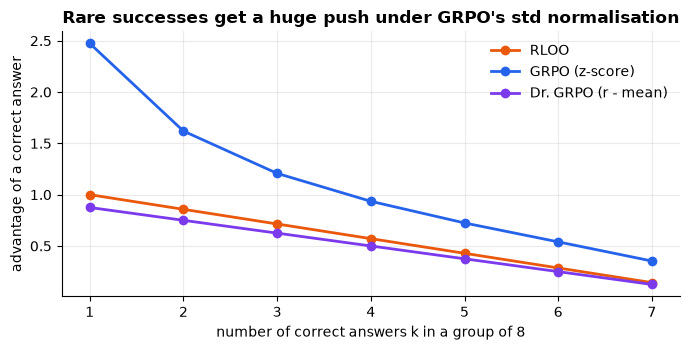

In [14]:
G_demo = 8
ks = np.arange(1, G_demo)
rows = {"RLOO": [], "GRPO (z-score)": [], "Dr. GRPO (r - mean)": []}
for k in ks:
    r = torch.tensor([1.0] * k + [0.0] * (G_demo - k))
    b = {"r": r, "G": G_demo, "mask": torch.ones(G_demo, 1)}
    rows["RLOO"].append(rloo_advantage(b)[0, 0].item())
    rows["GRPO (z-score)"].append(grpo_advantage(b)[0, 0].item())
    rows["Dr. GRPO (r - mean)"].append((r - r.mean())[0].item())

fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, ys), c in zip(rows.items(), [COLORS["value"], COLORS["policy"], COLORS["accent"]]):
    ax.plot(ks, ys, "o-", lw=2, color=c, label=name)
ax.set_xlabel("number of correct answers k in a group of 8")
ax.set_ylabel("advantage of a correct answer")
ax.set_title("Rare successes get a huge push under GRPO's std normalisation")
ax.legend()
plt.tight_layout()
save_figure(fig, "09_advantage_vs_k.png")
plt.show()

Read the plot from left to right. When only 1 of 8 answers is correct (a *hard* prompt), GRPO multiplies
that answer's advantage by $1/\sigma \approx 2.8$. When 7 of 8 are correct (an *easy* prompt), the
z-score is again large for the wrong one. Dividing by $\sigma$ up-weights prompts that are very hard or
very easy for the model. Dr. GRPO (§7) calls this a bias and removes it.

### 6.1 · Training GRPO and watching one group

We train GRPO and, every 5 steps, look at one fixed prompt `"3+4="`. We draw 8 samples, score them,
turn the rewards into group advantages, and show the policy's probability for the first answer token.
The GIF shows the whole GRPO step running over and over. Green chips are correct and get positive
advantages, which pull probability mass toward `7`.

In [15]:
WATCH_PROMPT, WATCH_ANSWER = "3+4=", "7"
watch_ids = torch.tensor([TOK.encode(WATCH_PROMPT)] * 8)
DIGITS = [str(d) for d in range(10)] + ["<eos>"]
DIGIT_IDS = [TOK.stoi[d] for d in DIGITS[:-1]] + [TOK.EOS]
group_frames, grid_frames = [], []


def snapshot_hook(step, policy, batch, adv):
    """Record the fixed-prompt group (every 5 steps) and the 6x6 greedy answer grid (every 10)."""
    if step % 5 and step != 199:
        return
    rng_state = torch.get_rng_state()           # don't perturb the training randomness
    with torch.no_grad():
        seq, _ = generate(policy, watch_ids, MAX_NEW, temperature=1.0)
        logits, _ = policy(watch_ids[:1])
        probs = F.softmax(logits[0, -1], dim=-1)[DIGIT_IDS].tolist()
    torch.set_rng_state(rng_state)
    answers = [TOK.decode(s[PROMPT_LEN:]) for s in seq.tolist()]
    r = torch.tensor([float(a == WATCH_ANSWER) for a in answers])
    a = ((r - r.mean()) / (r.std() + 1e-4)).tolist()
    group_frames.append({"step": step, "answers": answers, "r": r.tolist(), "adv": a, "probs": probs})
    if step % 10 == 0 or step == 199:
        ids = torch.tensor([TOK.encode(p) for p, _ in PROBLEMS])
        gseq, _ = generate(policy, ids, MAX_NEW, greedy=True)
        outs = [TOK.decode(s[PROMPT_LEN:]) for s in gseq.tolist()]
        grid_frames.append({"step": step, "outs": outs,
                            "ok": [o == ans for o, (_, ans) in zip(outs, PROBLEMS)]})


GRPO = Algorithm("GRPO", grpo_advantage, grpo_loss, color=COLORS["policy"])
GRPO_POLICY, RESULTS["GRPO"] = train(GRPO, hook=snapshot_hook)
report("GRPO", RESULTS["GRPO"])

GRPO         sampled reward 0.28 -> 0.90 | greedy acc 0.31 -> 0.94 | entropy 0.08 | len 2.00 | 22s


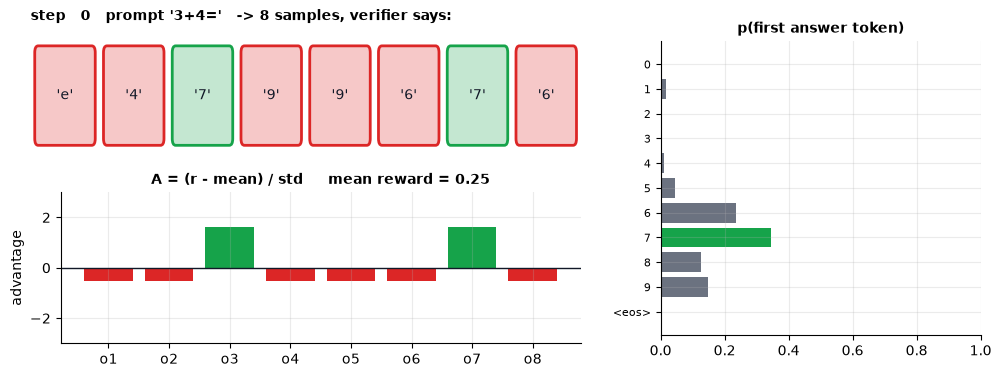


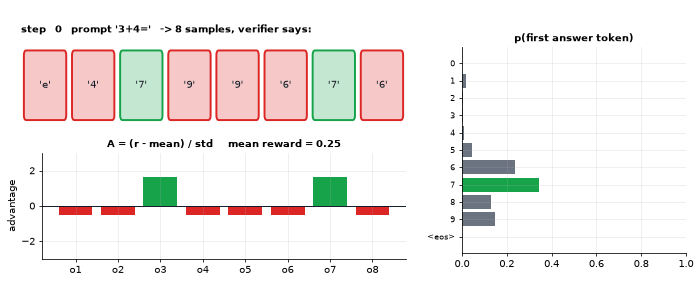

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/09_grpo_group.gif')

In [16]:
def draw_group(fig, i):
    """One GRPO step for the fixed prompt: samples -> rewards -> advantages -> policy distribution."""
    f = group_frames[i]
    fig.clf()
    ax_s = fig.add_axes([0.03, 0.55, 0.55, 0.32])
    ax_a = fig.add_axes([0.06, 0.12, 0.52, 0.36])
    ax_p = fig.add_axes([0.66, 0.14, 0.32, 0.70])
    # (1) the group of samples, coloured by reward
    ax_s.set_xlim(0, 8); ax_s.set_ylim(0, 1); ax_s.axis("off")
    ax_s.set_title(f"step {f['step']:3d}   prompt '{WATCH_PROMPT}'   -> 8 samples, verifier says:", loc="left", fontsize=10)
    for j, (ans, r) in enumerate(zip(f["answers"], f["r"])):
        c = COLORS["reward"] if r > 0 else COLORS["penalty"]
        draw_box(ax_s, (j + 0.08, 0.15), 0.84, 0.7, repr(ans) if ans else "''", c, fontsize=10, alpha=0.25)
    # (2) group-normalised advantages
    cols = [COLORS["reward"] if v > 0 else COLORS["penalty"] for v in f["adv"]]
    ax_a.bar(range(8), f["adv"], color=cols)
    ax_a.axhline(0, color=COLORS["ink"], lw=1)
    ax_a.set_ylim(-3, 3); ax_a.set_xticks(range(8)); ax_a.set_xticklabels([f"o{j + 1}" for j in range(8)])
    ax_a.set_ylabel("advantage")
    ax_a.set_title(f"A = (r - mean) / std     mean reward = {np.mean(f['r']):.2f}", fontsize=10)
    # (3) the policy's first-token distribution
    pc = [COLORS["reward"] if d == WATCH_ANSWER else COLORS["reference"] for d in DIGITS]
    ax_p.barh(range(len(DIGITS)), f["probs"], color=pc)
    ax_p.set_yticks(range(len(DIGITS))); ax_p.set_yticklabels(DIGITS, fontsize=8)
    ax_p.set_xlim(0, 1); ax_p.invert_yaxis()
    ax_p.set_title("p(first answer token)", fontsize=10)


show_frame(draw_group, 0, figsize=(10, 4.2))
Animator(draw_group, n_frames=len(group_frames), figsize=(10, 4.2), fps=5, dpi=70).save("09_grpo_group.gif")

Notice how the dynamics fit the formula. When all 8 chips are red or all green, the advantage bars
vanish and that step teaches nothing about this prompt. Learning happens on mixed groups.

The second animation shows **all 36 problems** at once. Each cell is the model's greedy answer to
`a+b=` (rows $a$, columns $b$), green when correct, next to the training reward curve:


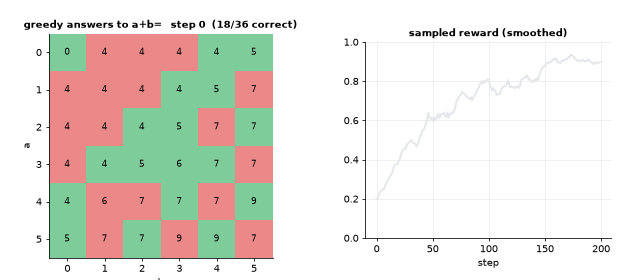

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/09_grpo_grid.gif')

In [17]:
def draw_grid(fig, i):
    f = grid_frames[i]
    fig.clf()
    ax = fig.add_axes([0.03, 0.08, 0.45, 0.8])
    ok = np.array(f["ok"], dtype=float).reshape(6, 6)
    ax.imshow(ok, cmap=plt.matplotlib.colors.ListedColormap([COLORS["penalty"], COLORS["reward"]]),
              vmin=0, vmax=1, alpha=0.55)
    for k, out in enumerate(f["outs"]):
        ax.text(k % 6, k // 6, out if out else "''", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(6)); ax.set_yticks(range(6)); ax.grid(False)
    ax.set_xlabel("b"); ax.set_ylabel("a")
    ax.set_title(f"greedy answers to a+b=   step {f['step']}  ({int(ok.sum())}/36 correct)", fontsize=10)
    ax2 = fig.add_axes([0.58, 0.15, 0.39, 0.7])
    rew = smooth(RESULTS["GRPO"]["reward"], 10)
    ax2.plot(rew, color=COLORS["light"], lw=2)
    ax2.plot(rew[: f["step"] + 1], color=COLORS["policy"], lw=2.5)
    ax2.set_ylim(0, 1); ax2.set_xlabel("step"); ax2.set_title("sampled reward (smoothed)", fontsize=10)


Animator(draw_grid, n_frames=len(grid_frames), figsize=(9, 4), fps=3, dpi=70).save("09_grpo_grid.gif")

## 7 · Dr. GRPO: removing GRPO's two hidden biases

**Paper.** Liu et al., 2025, *"Understanding R1-Zero-Like Training: A Critical Perspective"*. "Dr." stands for
**GRPO Done Right**.

**Intuition.** Two harmless-looking normalisations in GRPO change *what* is being optimised:

1. **Length bias, from $\frac{1}{|o_i|}$.** Each response's token losses are averaged over its own length.
   For a **wrong** answer ($\hat A<0$), a longer response spreads the same penalty over more tokens, so each
   token is punished less. The model learns that being wrong at length is cheaper, and incorrect answers grow
   longer. The paper links some of the "response length keeps growing" seen in R1-Zero-style runs to this.
2. **Difficulty bias, from $\frac{1}{\operatorname{std}}$.** As the previous figure showed, groups with small
   reward variance (very easy or very hard questions) get their advantages blown up.

**Math.** Dr. GRPO uses the plain group-mean baseline and a **constant** normaliser:

$$\hat A_i = r_i - \operatorname{mean}(r_{1..G}),\qquad
\mathcal{L} = -\frac{1}{G\cdot L_{\max}}\sum_{i=1}^{G}\sum_{t=1}^{|o_i|}\min\big(\rho_{i,t}\hat A_i,\ \operatorname{clip}(\rho_{i,t})\hat A_i\big).$$

Now each token's gradient weight is independent of how long its response happens to be. The objective is
again an unbiased policy gradient (up to the constant). The paper also drops the KL term for verifiable
rewards.

**Algorithm steps**

1. **Sample** and **score** as in GRPO.
2. **Advantage** $=r_i-\bar r$, without dividing by std.
3. **Clipped surrogate** per token.
4. **Aggregate** by summing over all tokens and dividing by the constant $G\cdot L_{\max}$, not by $|o_i|$.

In [18]:
def dr_grpo_advantage(batch):
    """Group-mean baseline only (no std division)."""
    g = batch["r"].view(-1, batch["G"])
    return broadcast((g - g.mean(1, keepdim=True)).flatten(), batch["mask"])


def dr_grpo_loss(logp, adv, batch):
    return agg_constant(ppo_clip_per_token(logp, batch["old_logp"], adv), batch["mask"])


# The length bias in one line: two wrong answers (same A < 0) of length 1 and 4 tokens.
m = torch.tensor([[1., 0, 0, 0], [1., 1, 1, 1]])
print("per-token weight under sequence-mean:", (m / m.sum(1, keepdim=True))[:, 0].tolist(),
      "-> the long wrong answer is punished 4x less per token")
print("per-token weight under constant     :", (m / (2 * 4))[:, 0].tolist(), "-> equal")

per-token weight under sequence-mean: [1.0, 0.25] -> the long wrong answer is punished 4x less per token
per-token weight under constant     : [0.125, 0.125] -> equal


In [19]:
DR_GRPO = Algorithm("Dr. GRPO", dr_grpo_advantage, dr_grpo_loss, color=COLORS["accent"])
_, RESULTS["Dr. GRPO"] = train(DR_GRPO)
report("Dr. GRPO", RESULTS["Dr. GRPO"])

Dr. GRPO     sampled reward 0.25 -> 0.80 | greedy acc 0.31 -> 0.69 | entropy 0.03 | len 2.00 | 22s


## 8 · DAPO: four engineering fixes for long-CoT RL

**Paper.** Yu et al., 2025, *"DAPO: An Open-Source LLM Reinforcement Learning System at Scale"*
(ByteDance Seed and Tsinghua AIR). DAPO = **D**ecoupled Clip and **D**ynamic s**A**mpling **P**olicy
**O**ptimization. With Qwen2.5-32B it reported 50 points on AIME 2024 using fewer training steps than
DeepSeek's R1-Zero-Qwen-32B. DAPO drops the KL term entirely.

```mermaid
flowchart TB
    S["sample G answers per prompt"] --> SC["score: accuracy + overlong shaping (fix 4)"]
    SC --> F{"all G rewards equal?"}
    F -- yes --> D["drop group (fix 2: dynamic sampling)"] --> S
    F -- no --> K["keep group"]
    K --> B{"batch full?"}
    B -- no --> S
    B -- yes --> A["advantages = group z-score"]
    A --> L["clipped loss with eps_low = 0.2, eps_high = 0.28 (fix 1: clip-higher)"]
    L --> T["average over ALL tokens in the batch (fix 3: token-level loss)"]
    T --> U["gradient step"]
```

**The four fixes, with their intuition:**

1. **Clip-Higher.** PPO clips $\rho$ to $[0.8, 1.2]$. For a token with $\pi_{\text{old}}=0.01$, the most its
   probability can rise in one update is to $0.012$. For a token at $0.9$ the cap is $1.08$, effectively no
   cap. Symmetric clipping therefore lets confident tokens get more confident and stops rare,
   exploratory tokens from growing, and **entropy collapses**. DAPO decouples the bounds:
   $\operatorname{clip}(\rho, 1-\varepsilon_{\text{low}}, 1+\varepsilon_{\text{high}})$ with
   $\varepsilon_{\text{low}}=0.2$, $\varepsilon_{\text{high}}=0.28$.
2. **Dynamic Sampling.** Groups where every answer is right, or every answer is wrong, have zero
   advantage and contribute only noise and wasted compute. As the model improves, more groups become all
   correct, so the *effective* batch shrinks. DAPO over-samples and keeps only groups with
   $0<\#\text{correct}<G$.
3. **Token-level policy-gradient loss.** Average over all tokens in the batch instead of per sequence, so
   long responses are not down-weighted. This is the length issue from §7 again, solved the other way.
4. **Overlong reward shaping.** Truncated responses get a soft length penalty instead of being treated as
   wrong. With maximum length $L_{\max}$ and a buffer $L_{\text{cache}}$:

$$R_{\text{length}}(y)=\begin{cases}0 & |y|\le L_{\max}-L_{\text{cache}}\\[2pt]
\dfrac{(L_{\max}-L_{\text{cache}})-|y|}{L_{\text{cache}}} & L_{\max}-L_{\text{cache}}<|y|\le L_{\max}\\[6pt]
-1 & |y|>L_{\max}\end{cases}$$

**Algorithm steps**

1. **Over-sample** prompts × $G$ responses.
2. **Score** with accuracy plus the overlong penalty.
3. **Filter** groups with zero reward variance and keep sampling until the batch is full.
4. **Group-normalise** the advantages.
5. **Decoupled clipping** with $\varepsilon_{\text{high}} > \varepsilon_{\text{low}}$.
6. **Token-mean aggregation**, no KL term, gradient step.

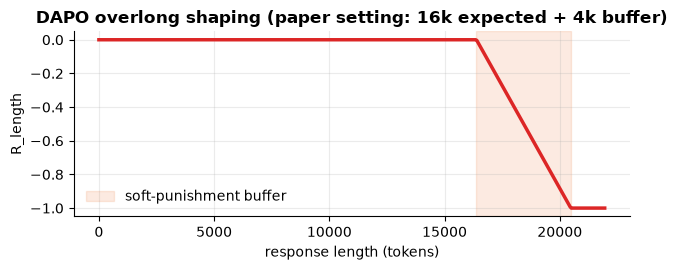

In [20]:
def overlong_penalty(lengths, L_max, L_cache):
    """DAPO soft overlong punishment; `lengths` are response lengths in tokens."""
    lengths = lengths.float()
    soft = ((L_max - L_cache) - lengths) / L_cache
    return torch.where(lengths <= L_max - L_cache, torch.zeros_like(lengths),
                       torch.where(lengths <= L_max, soft, -torch.ones_like(lengths)))


Ls = torch.arange(0, 22000, 50)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.plot(Ls, overlong_penalty(Ls, 20480, 4096), color=COLORS["penalty"], lw=2.5)
ax.axvspan(16384, 20480, color=COLORS["value"], alpha=0.12, label="soft-punishment buffer")
ax.set_xlabel("response length (tokens)"); ax.set_ylabel("R_length")
ax.set_title("DAPO overlong shaping (paper setting: 16k expected + 4k buffer)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()


def dapo_shaping(batch):
    """Toy setting: generation is capped at MAX_NEW=4, so allow up to 3 tokens and punish the 4th."""
    return overlong_penalty(batch["mask"].sum(1), L_max=MAX_NEW, L_cache=1)


def dapo_loss(logp, adv, batch, eps_low=0.2, eps_high=0.28):
    per_tok = ppo_clip_per_token(logp, batch["old_logp"], adv, eps_low, eps_high)
    return agg_token_mean(per_tok, batch["mask"])

The clip region is easier to grasp as a picture. Below is the per-token surrogate $\min(\rho A,
\operatorname{clip}(\rho)A)$ as a function of $\rho$, and on the right **the largest probability a token can
reach in one update**, as a function of its old probability:

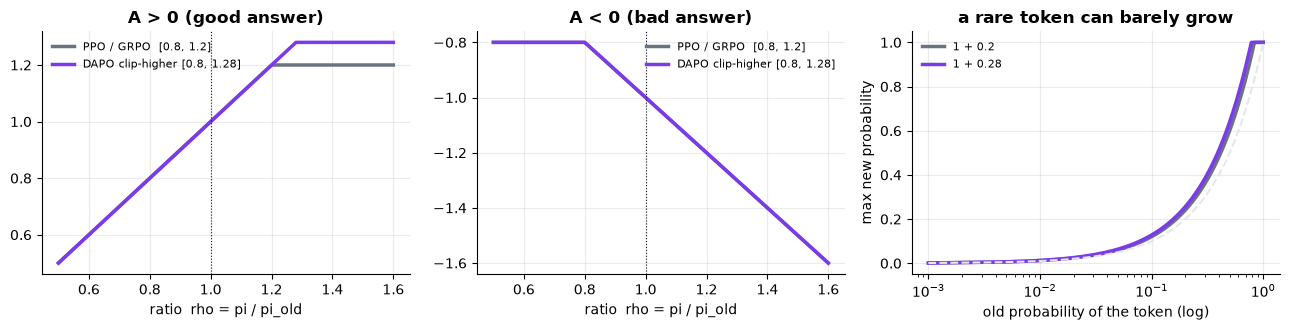

In [21]:
rho = np.linspace(0.5, 1.6, 400)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, A, title in [(axes[0], 1.0, "A > 0 (good answer)"), (axes[1], -1.0, "A < 0 (bad answer)")]:
    for (lo, hi), c, lab in [((0.2, 0.2), COLORS["reference"], "PPO / GRPO  [0.8, 1.2]"),
                             ((0.2, 0.28), COLORS["accent"], "DAPO clip-higher [0.8, 1.28]")]:
        surr = np.minimum(rho * A, np.clip(rho, 1 - lo, 1 + hi) * A)
        ax.plot(rho, surr, color=c, lw=2.5, label=lab)
    ax.axvline(1, color=COLORS["ink"], lw=0.8, ls=":")
    ax.set_xlabel("ratio  rho = pi / pi_old"); ax.set_title(title); ax.legend(fontsize=8)
p_old = np.linspace(0.001, 1, 300)
axes[2].plot(p_old, np.minimum(1, p_old * 1.2), color=COLORS["reference"], lw=2.5, label="1 + 0.2")
axes[2].plot(p_old, np.minimum(1, p_old * 1.28), color=COLORS["accent"], lw=2.5, label="1 + 0.28")
axes[2].plot(p_old, p_old, color=COLORS["light"], lw=1.5, ls="--")
axes[2].set_xscale("log"); axes[2].set_xlabel("old probability of the token (log)")
axes[2].set_ylabel("max new probability"); axes[2].set_title("a rare token can barely grow"); axes[2].legend(fontsize=8)
plt.tight_layout()
save_figure(fig, "09_clip_regions.png")
plt.show()

In [22]:
DAPO = Algorithm("DAPO", grpo_advantage, dapo_loss, dynamic_sampling=True, reward_shaping=dapo_shaping,
                 color=COLORS["value"])
_, RESULTS["DAPO"] = train(DAPO)
report("DAPO", RESULTS["DAPO"])
print(f"zero-variance groups that GRPO trained on (late training): "
      f"{np.mean(RESULTS['GRPO']['zero_var_groups'][-50:]):.0%};  DAPO after filtering: "
      f"{np.mean(RESULTS['DAPO']['zero_var_groups'][-50:]):.0%}")

DAPO         sampled reward 0.30 -> 0.88 | greedy acc 0.31 -> 0.89 | entropy 0.02 | len 2.02 | 24s
zero-variance groups that GRPO trained on (late training): 69%;  DAPO after filtering: 59%


## 9 · GSPO: importance ratios per sequence, not per token

**Paper.** Zheng et al., 2025, *"Group Sequence Policy Optimization"* (Qwen team). It was used for the
Qwen3 models.

**Intuition.** The reward is given to the **whole sequence**, but GRPO corrects for off-policy data with
**per-token** ratios $\rho_{i,t}$. Each of those is a noisy one-sample importance weight, and over thousands
of tokens the noise adds up. That is especially bad for Mixture-of-Experts models, where routing can
change between rollout and training. GSPO's view: the unit of reward should also be the unit of
importance sampling and clipping.

**Math.** A length-normalised (geometric-mean) sequence ratio:

$$s_i(\theta)=\left(\frac{\pi_\theta(y_i\mid x)}{\pi_{\text{old}}(y_i\mid x)}\right)^{1/|y_i|}
=\exp\Big(\frac{1}{|y_i|}\sum_t\log\frac{\pi_\theta(y_{i,t}\mid x,y_{i,<t})}{\pi_{\text{old}}(y_{i,t}\mid x,y_{i,<t})}\Big)$$

$$\mathcal{J}_{\text{GSPO}}=\mathbb{E}\Big[\frac1G\sum_i\min\big(s_i\hat A_i,\ \operatorname{clip}(s_i,1-\varepsilon,1+\varepsilon)\hat A_i\big)\Big],
\qquad \hat A_i=\text{group z-score}.$$

Because $s_i$ is a geometric mean, it stays close to 1, so GSPO uses **tiny** clip ranges. The paper reports
$\varepsilon_{\text{left}}=3\times10^{-4}$ and $\varepsilon_{\text{right}}=4\times10^{-4}$. Whole sequences
are clipped or kept together.

**Algorithm steps**

1. **Sample**, **score** and **group-normalise** as in GRPO.
2. **Sequence ratio.** Average the per-token log-ratio over the response and exponentiate.
3. **Clip at the sequence level** with a tiny $\varepsilon$. A sequence is either in or out.
4. **Average over sequences** and take a gradient step.

In [23]:
def gspo_loss(logp, adv, batch, eps_low=3e-4, eps_high=4e-4):
    mask = batch["mask"]
    seq_adv = (adv * mask).sum(1) / mask.sum(1).clamp(min=1)          # recover A_i from the broadcast
    log_s = masked_mean(logp - batch["old_logp"], mask, dim=1)        # mean log-ratio per sequence
    s = torch.exp(log_s)
    return -torch.min(s * seq_adv, s.clamp(1 - eps_low, 1 + eps_high) * seq_adv).mean()

In [24]:
GSPO = Algorithm("GSPO", grpo_advantage, gspo_loss, color="#db2777")
_, RESULTS["GSPO"] = train(GSPO)
report("GSPO", RESULTS["GSPO"])

GSPO         sampled reward 0.24 -> 0.65 | greedy acc 0.31 -> 0.67 | entropy 0.20 | len 2.02 | 26s


## 10 · CISPO: clip the weight, never the gradient (brief)

**Paper.** MiniMax, 2025, *"MiniMax-M1: Scaling Test-Time Compute Efficiently with Lightning Attention"*.

**Intuition.** When PPO/GRPO clips a token, that token's gradient becomes **zero**. The paper observed that
the clipped tokens were often rare "fork" tokens such as *However*, *Wait* or *Recheck*. These are exactly
the tokens that open up reflective reasoning. CISPO keeps every token's gradient and only bounds the
**importance-sampling weight**, which is treated as a constant (stop-gradient):

$$\mathcal{J}_{\text{CISPO}}=\mathbb{E}\Big[\frac{1}{\sum_i|o_i|}\sum_i\sum_t
\operatorname{sg}\big(\hat\rho_{i,t}\big)\,\hat A_{i}\,\log\pi_\theta(o_{i,t})\Big],\qquad
\hat\rho_{i,t}=\operatorname{clip}\big(\rho_{i,t},\,1-\varepsilon^{IS}_{\text{low}},\,1+\varepsilon^{IS}_{\text{high}}\big).$$

It is a REINFORCE-style loss with a bounded off-policy correction. MiniMax-M1 effectively uses only the upper
bound.

In [25]:
def cispo_loss(logp, adv, batch, eps_high=0.28):
    weight = torch.exp(logp - batch["old_logp"]).clamp(max=1 + eps_high).detach()   # sg(clip(rho))
    return agg_token_mean(-weight * adv * logp, batch["mask"])

In [26]:
CISPO = Algorithm("CISPO", grpo_advantage, cispo_loss, color="#65a30d")
_, RESULTS["CISPO"] = train(CISPO)
report("CISPO", RESULTS["CISPO"])

CISPO        sampled reward 0.25 -> 0.82 | greedy acc 0.31 -> 0.81 | entropy 0.11 | len 2.07 | 22s


## 11 · Head-to-head

Every method used the **same** warm-started policy, the same seed, the same task and the same sample budget
(16 prompts × 8 samples per step, 200 steps). Treat the result as one seed on a toy problem. The point is to
see the mechanisms, not to rank the methods. Real-world rankings depend on the model, the task and the
tuning.

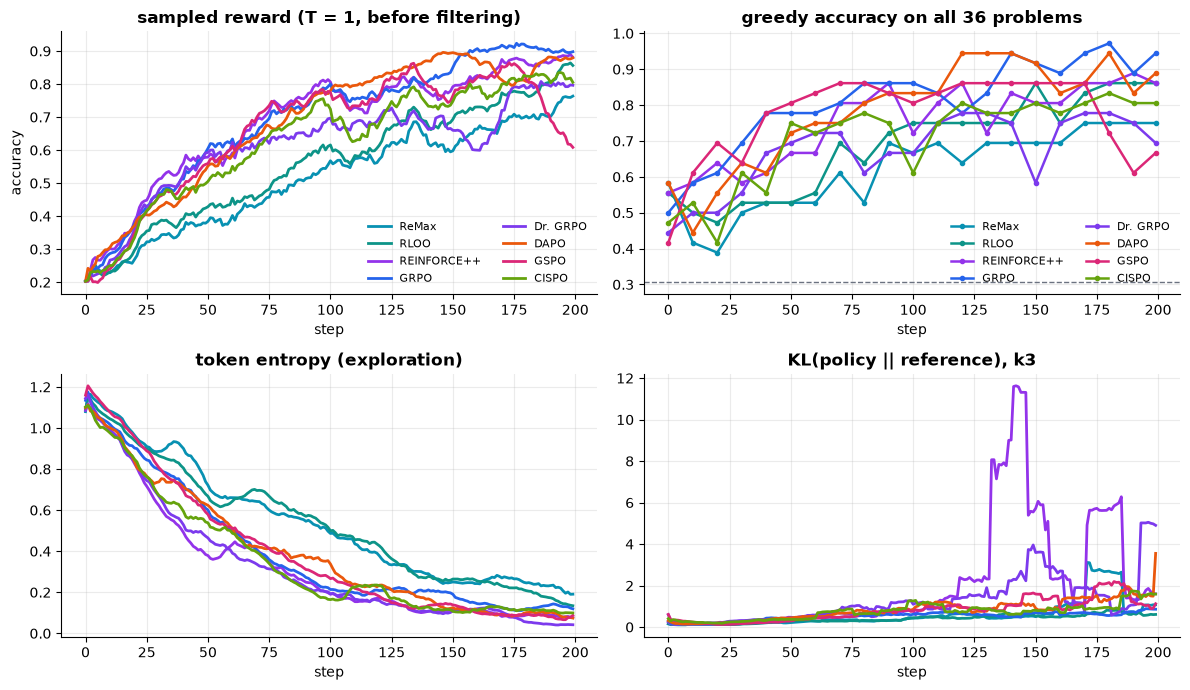

method       greedy acc final reward  entropy  length     KL   sec
ReMax              0.75         0.74     0.16    2.01  0.288    22
RLOO               0.86         0.84     0.13    2.00  0.357    20
REINFORCE++        0.86         0.88     0.06    2.00  1.115    26
GRPO               0.94         0.90     0.08    2.01  0.797    22
Dr. GRPO           0.69         0.80     0.03    2.00  0.490    22
DAPO               0.89         0.88     0.02    2.00 33.122    24
GSPO               0.67         0.65     0.20    2.00  4.161    26
CISPO              0.81         0.82     0.11    2.01  0.738    22


In [27]:
names = list(RESULTS)
cols = {n: c.color for n, c in zip(names, [REMAX, RLOO, RPP, GRPO, DR_GRPO, DAPO, GSPO, CISPO])}
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_curves({n: RESULTS[n]["reward"] for n in names}, "sampled reward (T = 1, before filtering)", ylabel="accuracy",
            window=15, ax=axes[0, 0], colors=cols)
for n in names:
    axes[0, 1].plot(RESULTS[n]["eval_step"], RESULTS[n]["greedy_acc"], "o-", ms=3, lw=1.8, color=cols[n], label=n)
axes[0, 1].axhline(BASE_GREEDY, color=COLORS["reference"], ls="--", lw=1)
axes[0, 1].set_title("greedy accuracy on all 36 problems"); axes[0, 1].set_xlabel("step")
plot_curves({n: RESULTS[n]["entropy"] for n in names}, "token entropy (exploration)", window=15, ax=axes[1, 0], colors=cols)
plot_curves({n: RESULTS[n]["kl"] for n in names}, "KL(policy || reference), k3", window=15, ax=axes[1, 1], colors=cols)
axes[0, 0].legend(fontsize=8, ncol=2); axes[0, 1].legend(fontsize=8, ncol=2)
axes[1, 0].get_legend().remove(); axes[1, 1].get_legend().remove()
plt.tight_layout()
save_figure(fig, "09_head_to_head.png")
plt.show()

print(f"{'method':12s} {'greedy acc':>10s} {'final reward':>12s} {'entropy':>8s} {'length':>7s} {'KL':>6s} {'sec':>5s}")
for n in names:
    h = RESULTS[n]
    print(f"{n:12s} {h['greedy_acc'][-1]:10.2f} {np.mean(h['reward'][-20:]):12.2f} {h['entropy'][-1]:8.2f} "
          f"{np.mean(h['length'][-20:]):7.2f} {h['kl'][-1]:6.3f} {h['seconds']:5.0f}")

In [28]:
# The notebook doubles as a test: critic-free RL must beat the warm start.
final_acc = {n: RESULTS[n]["greedy_acc"][-1] for n in names}
assert final_acc["GRPO"] >= BASE_GREEDY + 0.2, final_acc
assert sum(a > BASE_GREEDY + 0.1 for a in final_acc.values()) >= 6, final_acc
assert np.mean(RESULTS["DAPO"]["zero_var_groups"][-50:]) <= np.mean(RESULTS["GRPO"]["zero_var_groups"][-50:]), \
    "dynamic sampling should train on fewer zero-variance groups"
print("all checks passed:", {k: round(v, 2) for k, v in final_acc.items()})

all checks passed: {'ReMax': 0.75, 'RLOO': 0.86, 'REINFORCE++': 0.86, 'GRPO': 0.94, 'Dr. GRPO': 0.69, 'DAPO': 0.89, 'GSPO': 0.67, 'CISPO': 0.81}


**How to read this on your own runs**

* **Reward / accuracy.** Every method learns from the same signal ("which of my siblings did better").
  On a task this small the differences are mostly noise from one seed.
* **Entropy.** Look for fast collapse. A policy that becomes certain early stops exploring, and then
  groups turn zero-variance. Clip-higher (DAPO) and CISPO's never-zero gradients were designed against
  this.
* **KL.** Methods with no KL term (Dr. GRPO, DAPO, GSPO, CISPO here) are free to drift further from the
  reference. For verifiable rewards that is usually fine. For a learned reward model it is how reward hacking
  starts (notebook 13).
* **Zero-variance groups.** GRPO's fraction of useless groups grows as the model improves. DAPO's filter
  keeps the effective batch full.

## 12 · Common pitfalls

| Symptom | Likely cause | Fix |
|---|---|---|
| reward flat from step 0 | every group all-correct or all-wrong (warm start too strong or too weak, temperature too low) | shorter/longer SFT, temperature ≈ 1, harder/easier prompts, dynamic sampling |
| entropy collapses, reward plateaus | symmetric clip + many epochs over-sharpen the policy | clip-higher, fewer epochs, entropy bonus, CISPO |
| response length keeps growing while accuracy doesn't | per-sequence length normalisation punishes long wrong answers less | token-level or constant normalisation (DAPO / Dr. GRPO) |
| training diverges with MoE / long sequences | per-token ratios are noisy, routing differs between rollout and training | sequence-level ratios (GSPO), routing replay |
| reward goes up but held-out quality goes down | reward hacking a learned RM; no KL | keep β·KL, better RM, verifiable rewards (notebook 13) |
| `std = 0` → NaNs | dividing by the std of an all-equal group | add ε, or skip zero-variance groups |
| advantages look right but nothing moves | `old_logp` computed *with* grad, or recomputed after the update | store `old_logp` under `no_grad` once, before the epochs |

## 13 · How this connects to real LLM and VLM training

* **DeepSeek-R1 (2025)** used GRPO with rule-based rewards (answer correctness plus a format check)
  to train reasoning from a base model ("R1-Zero"). Notebook 10 rebuilds that recipe on a toy.
* At scale the loop is identical, but rollouts come from a fast inference engine (vLLM/SGLang) and the
  update runs in a distributed trainer. The policy weights are synchronised between them after each step.
  Notebook 13 covers the systems side and the off-policy corrections it needs.
* **VLMs** use exactly the same code. The prompt simply contains image tokens. Visual-RFT and VLM-R1 run
  GRPO with IoU or accuracy rewards on grounding and counting tasks (notebook 12).
* Group size is the main knob: larger $G$ gives a better baseline and fewer zero-variance groups, but costs more
  samples. Production runs use $G$ = 8 to 64.
* This repository's `hale_llm.rl` package and `01_online_rl.ipynb` apply the same GRPO step to
  **diffusion** LLMs. There the sequence log-probability is estimated (d1-style), not computed exactly.

## 14 · Cheat sheet

| Method | Year | Baseline / advantage | Ratio & clipping | Loss aggregation | KL | Key idea |
|---|---|---|---|---|---|---|
| ReMax | 2023 | $r_i - r(\text{greedy})$ | none (on-policy) | per response | (in reward, optional) | greedy decode as baseline |
| RLOO | 2024 | $r_i - \text{mean}_{j\ne i} r_j$ | none (on-policy) | per response | (in reward, optional) | leave-one-out, exactly unbiased |
| REINFORCE++ | 2025 | KL-shaped return, **batch** z-score | token, $[1\pm0.2]$ | token-mean | per-token in reward | PPO tricks without critic |
| GRPO | 2024 | **group** z-score | token, $[1\pm0.2]$ | sequence-mean | $k_3$ in loss, β=0.04 | DeepSeekMath / R1 workhorse |
| Dr. GRPO | 2025 | $r_i - \bar r$ (no std) | token, $[1\pm0.2]$ | constant $G L_{\max}$ | none | removes length & difficulty bias |
| DAPO | 2025 | group z-score | token, $[0.8, 1.28]$ | token-mean | none | clip-higher, dynamic sampling, overlong shaping |
| GSPO | 2025 | group z-score | **sequence** geo-mean, $\sim10^{-4}$ | per sequence | none | importance ratio matches the reward's unit |
| CISPO | 2025 | group z-score | clip IS **weight**, stop-grad | token-mean | none | never zero a token's gradient |

**One-sentence summary.** Sample a group, compare each answer with its siblings, push up the better ones
in a clipped, KL-aware way. Everything else in this family decides what "compare" and "clipped"
precisely mean.